# Labjournaal BM
## General
Template for labjournaal. See https://jupyter-notebook.readthedocs.io/en/stable/examples/Notebook/Working%20With%20Markdown%20Cells.html for options to use markdown.

**Name:**  Lara Topalovic-Henn

**Title of the experiment:**  BM

**Starting date:** 11/11/2026

**Expected enddate:** 11/11/2026

**Partner:** Dominic

**Goal of the experiment:**  
Bepalen van de constante van Boltzmann met behulp van een experment over spanningsmeter.

**Research question:**  

**Expectations or Hypothesis:**  

**Desired accuracy:**  




In [1]:
#import necessary libraries
import matplotlib.pyplot as plt
import numpy as np
from scipy.optimize import curve_fit 

# Preparation
 


**Assignments:**  

**Method:**  
**Theory:**  
**Independent variable:**  
**Dependent variable:**  
**Controlled variablen:**  
**Measurement instruments \& Settings:**  
**Procedure:**  
**Setup(drawing or picture):**  
**Notes:**  
**About accuracy:**  


# Execution

Is  = 2.685e-09 ± 3.5e-10 A
a   = 23.2 ± 1.1 1/V
k_B = 1.157e-23 ± 8.0e-25 J/K   (literatuur: 1.381e-23)


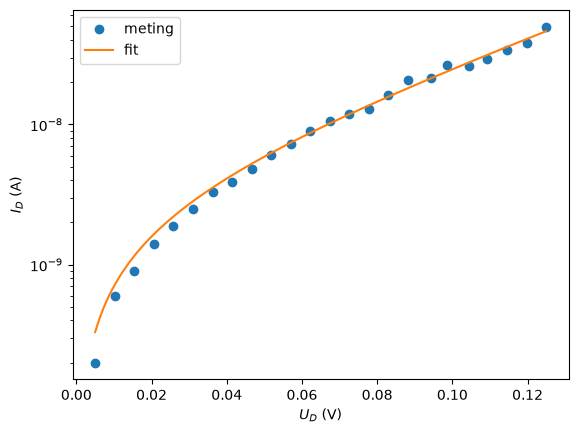

In [ ]:
from scipy.constants import e as q

def shockley(V, Is, a):
    return Is * (np.exp(a * V) - 1)

# Deze functie zorgt ervoor dat we de juiste startwaarde vinden voor de fit
# van de shockley functie
def lijn(x, c, d):
    return c * x + d

R = 10000
R2 = 470
R3 = 10
n = 2.0
sn = 0.1

temp_avg = np.array([24.904, 24.952, 24.956, 24.954, 24.933,
                     24.946, 24.972, 24.980, 24.954, 24.986])
# De temperatuur in Kelvin
T  = np.mean(temp_avg) + 273.15
sT = 1.0

USB = np.array([6.02, 5.77, 5.52, 5.26, 5.02, 4.74, 4.54, 4.24, 3.99, 3.74, 3.49, 3.24,
                2.99, 2.74, 2.49, 2.24, 1.99, 1.74, 1.49, 1.24, 0.99, 0.74, 0.49, 0.24])
VR1 = np.array([0.498, 0.379, 0.342, 0.295, 0.261, 0.266, 0.216, 0.208, 0.161, 0.129,
                0.119, 0.105, 0.090, 0.072, 0.061, 0.048, 0.039, 0.033, 0.025, 0.019,
                0.014, 0.009, 0.006, 0.002]) / 1e3

I_D = VR1 / R
U = R3 / (R2 + R3) * USB
U_D = U - VR1

# Voor het vinden van die startwaarde gebruiken we een fit met een rechte lijn, wat we in principe verwachten van de grafiek.
# We willen alleen punten die boven de 0.03 uitkomen, I_d > 0 omdat je niet de log van <= 0 kan nemen.
# p0 rekent de parameters om naar waarden die passen bij de shockley functie

mask = (U_D > 0.03) & (I_D > 0)
(c, d), _ = curve_fit(lijn, U_D[mask], np.log10(I_D[mask]))
p0 = [10 ** d, c / np.log10(np.e)]

# De daadwerkelijke fit op de Shockley functie
popt, pcov = curve_fit(shockley, U_D, I_D, p0=p0)
Is, a = popt
sIs, sa = np.sqrt(np.diag(pcov))

# Constante van Boltzmann met onzekerheid
kB  = q / (a * n * T)
skB = kB * np.sqrt((sa / a)**2 + (sn / n)**2 + (sT / T)**2)

print(f"Is  = {Is:.3e} ± {sIs:.1e} A")
print(f"a   = {a:.3g} ± {sa:.2g} 1/V")
print(f"k_B = {kB:.3e} ± {skB:.1e} J/K   (literatuur: 1.381e-23)")

V = np.linspace(U_D.min(), U_D.max(), 500)
plt.semilogy(U_D, I_D, 'o', label='meting')
plt.semilogy(V, shockley(V, *popt), label='fit')
plt.xlabel('$U_D$ (V)')
plt.ylabel('$I_D$ (A)')
plt.legend()
plt.show()

**Observations:**  
**Notes:**  

# Processing
**Description of processing of raw data into scientific evidence:**


In [3]:
#Data processing and analysis:


In [4]:
#Data processing and analysis:


In [5]:
#Data processing and analysis:


**Describing the pattern in the processed data:**  


In [6]:
#Calculations of e.a. measurement uncertainties, and providing final answers.


**Notes:**  

# Discussion



# Conclusion

# Additional notes, remarks, explanations, thoughts etc